In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
df=pd.read_excel(r"C:\Users\HP\OneDrive\Desktop\Apex planet task 3rd.xlsx")


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Order_ID       1000 non-null   str           
 1   Order_Date     1000 non-null   datetime64[us]
 2   Customer_ID    1000 non-null   str           
 3   Customer_Name  1000 non-null   str           
 4   Age            1000 non-null   int64         
 5   Gender         1000 non-null   str           
 6   City           1000 non-null   str           
 7   Product        1000 non-null   str           
 8   Category       1000 non-null   str           
 9   Quantity       1000 non-null   int64         
 10  Unit_Price     1000 non-null   float64       
 11  Total_Sales    1000 non-null   float64       
dtypes: datetime64[us](1), float64(2), int64(2), str(7)
memory usage: 146.7 KB


In [12]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Order_ID       1000 non-null   str           
 1   Order_Date     1000 non-null   datetime64[us]
 2   Customer_ID    1000 non-null   str           
 3   Customer_Name  1000 non-null   str           
 4   Age            1000 non-null   int64         
 5   Gender         1000 non-null   str           
 6   City           1000 non-null   str           
 7   Product        1000 non-null   str           
 8   Category       1000 non-null   str           
 9   Quantity       1000 non-null   int64         
 10  Unit_Price     1000 non-null   float64       
 11  Total_Sales    1000 non-null   float64       
dtypes: datetime64[us](1), float64(2), int64(2), str(7)
memory usage: 146.7 KB


In [13]:
sum=df["Total_Sales"].sum()
print("Total sales",sum)

Total sales 139399439.65


In [14]:
statistical_info=df.describe() # std is compare the difference b/w average to minand max
print(statistical_info)

                       Order_Date          Age     Quantity    Unit_Price  \
count                        1000  1000.000000  1000.000000   1000.000000   
mean   2025-07-03 11:19:40.800000    41.353000     5.435000  25486.783410   
min           2025-01-01 00:00:00    18.000000     1.000000    145.780000   
25%           2025-03-30 18:00:00    30.000000     3.000000  13895.722500   
50%           2025-07-01 00:00:00    41.000000     5.000000  25398.740000   
75%           2025-10-07 06:00:00    53.000000     8.000000  37512.382500   
max           2026-01-01 00:00:00    65.000000    10.000000  49997.530000   
std                           NaN    13.683626     2.838632  14179.402361   

         Total_Sales  
count    1000.000000  
mean   139399.439650  
min       437.340000  
25%     47066.632500  
50%    108594.025000  
75%    203722.882500  
max    493677.500000  
std    114100.051546  


In [15]:
gender_count=df["Gender"].value_counts()
print(gender_count)

Gender
Male      511
Female    489
Name: count, dtype: int64


In [16]:
product=df["Product"].value_counts()
print(product)

Product
Mobile    184
Book      178
Laptop    170
Chair     159
Shoes     156
Rice      153
Name: count, dtype: int64


In [17]:
category=df["Category"].value_counts()
print(category)

Category
Electronics    354
Education      178
Furniture      159
Fashion        156
Grocery        153
Name: count, dtype: int64


In [18]:
product_category=df.groupby("Category")["Product"].agg(["nunique","unique"])
print(product_category)

             nunique            unique
Category                              
Education          1            [Book]
Electronics        2  [Mobile, Laptop]
Fashion            1           [Shoes]
Furniture          1           [Chair]
Grocery            1            [Rice]


                                             Task 4 Important Statical Analysis

Lower Limit: -187917.7425
Upper Limit: 438707.2575
Outlier Count: 19


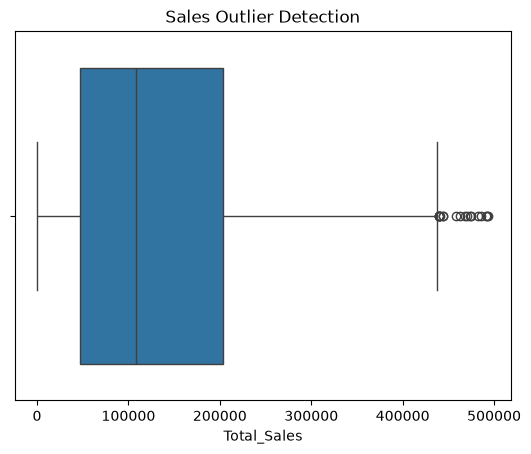

In [29]:
# Sales outlier Detection
Q1 = df["Total_Sales"].quantile(0.25)
Q3 = df["Total_Sales"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["Total_Sales"] < lower_limit) |
    (df["Total_Sales"] > upper_limit)
]

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
print("Outlier Count:", len(outliers))

sns.boxplot(x=df["Total_Sales"])
plt.title("Sales Outlier Detection")
plt.show()

                  Age  Quantity  Unit_Price  Total_Sales
Age          1.000000 -0.027666   -0.011955     0.001294
Quantity    -0.027666  1.000000    0.021855     0.646641
Unit_Price  -0.011955  0.021855    1.000000     0.686303
Total_Sales  0.001294  0.646641    0.686303     1.000000


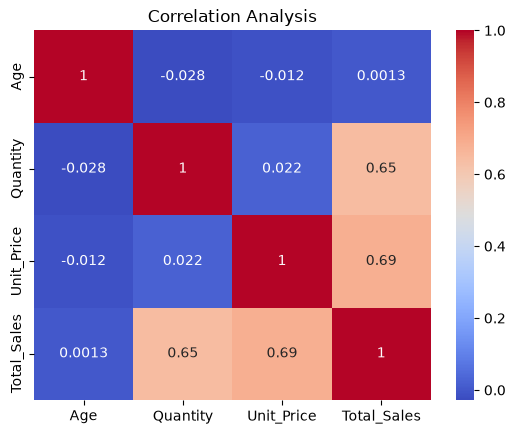

In [30]:
# Analysis 2 - Correlation Analysis
correlation = df[
    ["Age", "Quantity", "Unit_Price", "Total_Sales"]
].corr()

print(correlation)
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Analysis")
plt.show()

In [32]:
#Gender Wise T-Test
from scipy.stats import ttest_ind
customer_gender = df.groupby(
    ["Customer_ID", "Gender"]
)["Total_Sales"].mean().reset_index()

male = customer_gender[
    customer_gender["Gender"] == "Male"
]["Total_Sales"]

female = customer_gender[
    customer_gender["Gender"] == "Female"
]["Total_Sales"]

t_stat, p_value = ttest_ind(
    male, female, equal_var=False
)

print("Male Average:", male.mean())
print("Female Average:", female.mean())
print("T-Statistic:", t_stat)
print("P-Value:", p_value)

Male Average: 141822.214312749
Female Average: 136063.3456367432
T-Statistic: 0.7987577760556628
P-Value: 0.4246246083751343


In [34]:
# Chi-Square Test
from scipy.stats import chi2_contingency
table = pd.crosstab(
    df["Gender"],
    df["Category"]
)

chi2, p, dof, expected = chi2_contingency(table)

print("Chi-Square Value:", chi2)
print("P-Value:", p)
print("Degrees of Freedom:", dof)

Chi-Square Value: 9.093603101182486
P-Value: 0.058801960303009174
Degrees of Freedom: 4


In [36]:
#Anova Test
from scipy.stats import f_oneway
groups = [
    group["Total_Sales"].values
    for name, group in df.groupby("Category")
]

f_stat, p_value = f_oneway(*groups)

print("F-Statistic:", f_stat)
print("P-Value:", p_value)

F-Statistic: 0.7171167721714614
P-Value: 0.5802864995733577


In [39]:
# 95% Confidence Interval
from scipy import stats

sales = df["Total_Sales"].dropna()

mean = sales.mean()
sem = stats.sem(sales)

ci = stats.t.interval(
    confidence=0.95,
    df=len(sales)-1,
    loc=mean,
    scale=sem
)

print("Average Sales:", mean)
print("95% Confidence Interval:", ci)

Average Sales: 139399.43965000001
95% Confidence Interval: (np.float64(132318.9968196067), np.float64(146479.88248039334))


In [19]:
plt.show()

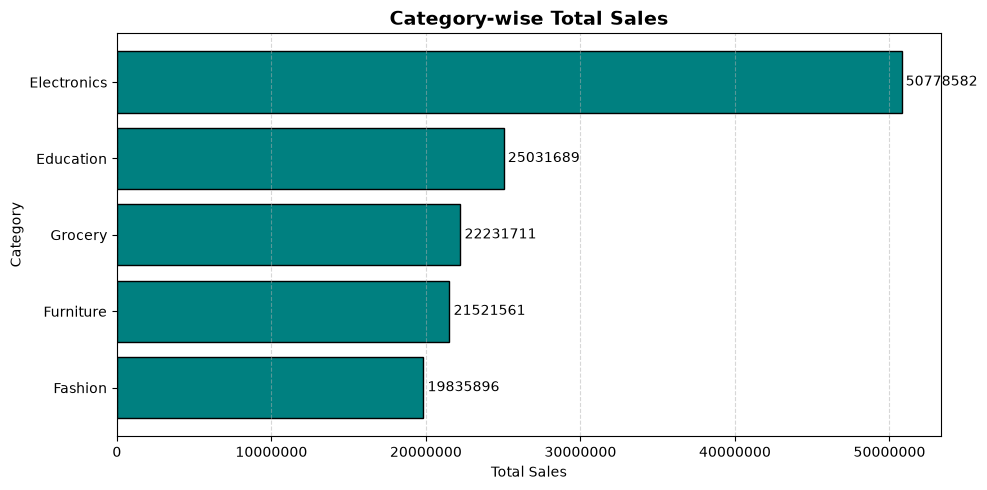

In [20]:


data = df.groupby("Category")["Total_Sales"].sum().sort_values()

plt.figure(figsize=(10, 5))
bars = plt.barh(data.index, data.values, color="teal", edgecolor="black")
plt.bar_label(bars, fmt="%.0f", padding=3)

plt.title("Category-wise Total Sales", fontsize=14, fontweight="bold")
plt.xlabel("Total Sales")
plt.ylabel("Category")
plt.ticklabel_format(axis="x", style="plain")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

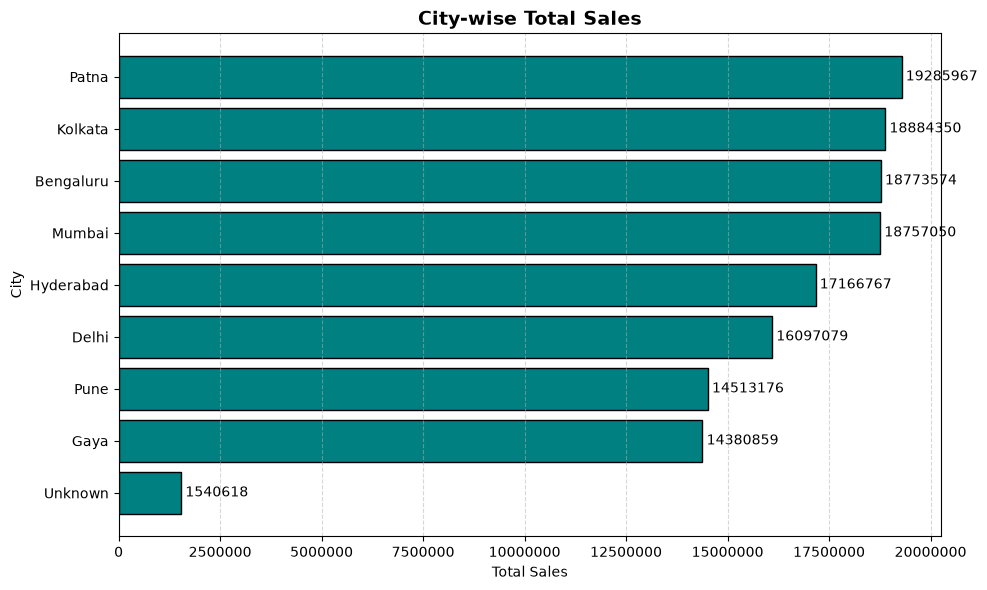

In [21]:
data = df.groupby("City")["Total_Sales"].sum().sort_values()

plt.figure(figsize=(10, 6))
bars = plt.barh(data.index, data.values, color="teal", edgecolor="black")
plt.bar_label(bars, fmt="%.0f", padding=3)

plt.title("City-wise Total Sales", fontsize=14, fontweight="bold")
plt.xlabel("Total Sales")
plt.ylabel("City")
plt.ticklabel_format(axis="x", style="plain")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

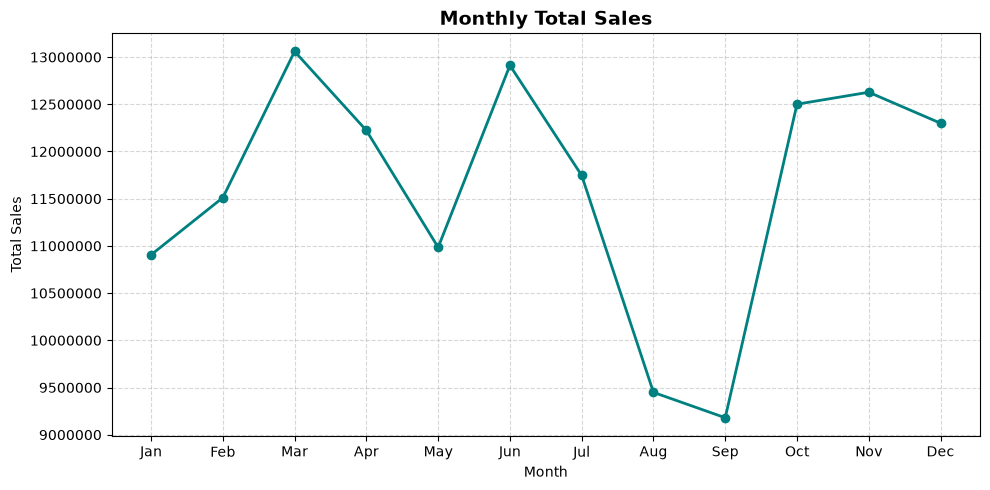

In [22]:

data = df.groupby(df["Order_Date"].dt.month)["Total_Sales"].sum()

plt.figure(figsize=(10, 5))
plt.plot(data.index, data.values, marker="o", color="teal", linewidth=2)

plt.xticks(range(1, 13), ["Jan","Feb","Mar","Apr","May","Jun",
                          "Jul","Aug","Sep","Oct","Nov","Dec"])

plt.title("Monthly Total Sales", fontsize=14, fontweight="bold")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.ticklabel_format(axis="y", style="plain")   # 1e7 hatane ke liye
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

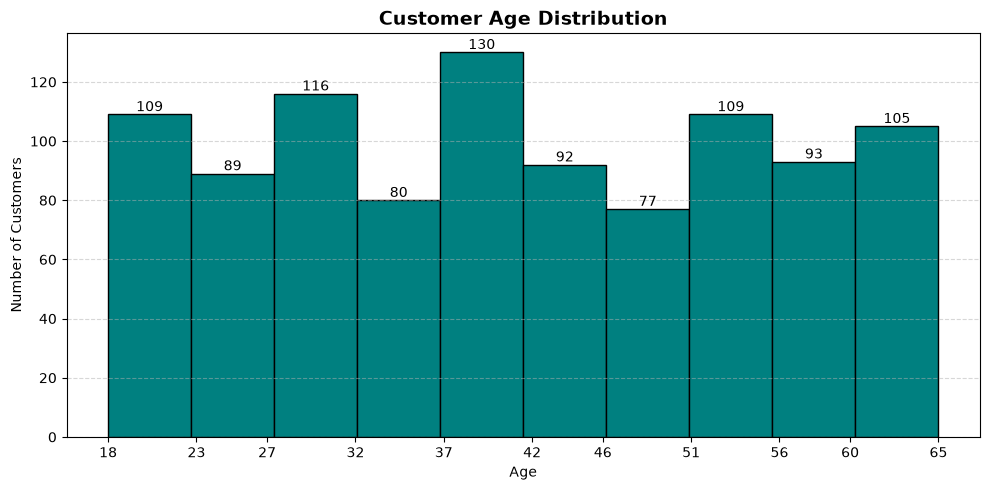

In [23]:

plt.figure(figsize=(10, 5))
counts, bins, patches = plt.hist(df["Age"], bins=10, color="teal", edgecolor="black")
plt.bar_label(patches, fmt="%.0f")

plt.title("Customer Age Distribution", fontsize=14, fontweight="bold")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.xticks(bins.round(0))
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

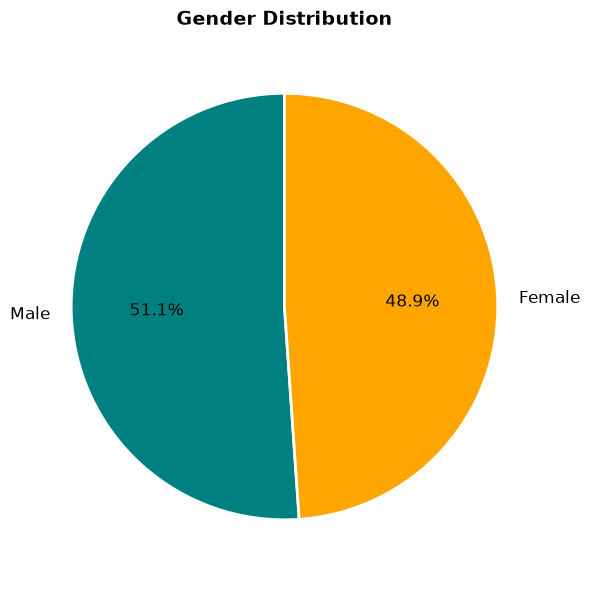

In [24]:


data = df["Gender"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(data.values, labels=data.index, autopct="%1.1f%%",
        colors=["teal", "orange"], startangle=90,
        wedgeprops={"edgecolor": "white", "linewidth": 2},
        textprops={"fontsize": 12})

plt.title("Gender Distribution", fontsize=14, fontweight="bold")
plt.axis("equal")   # chart gol rakhta hai
plt.tight_layout()
plt.show()

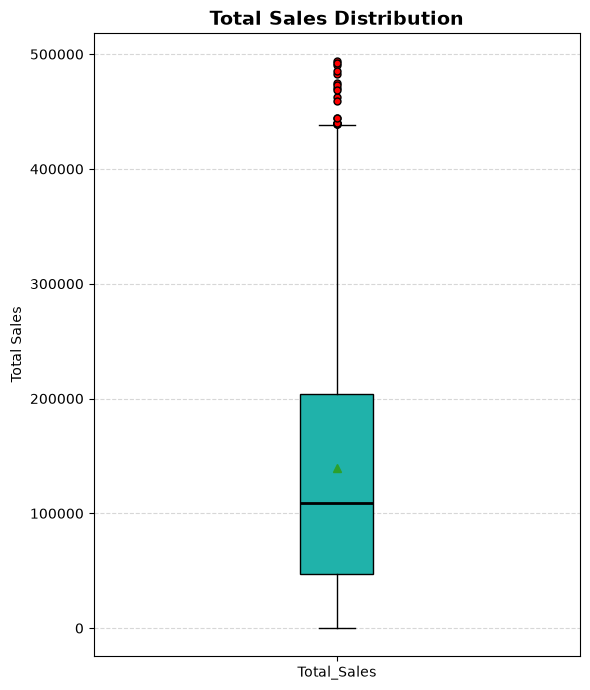

In [25]:
plt.figure(figsize=(6, 7))
plt.boxplot(df["Total_Sales"], patch_artist=True, showmeans=True,
            boxprops=dict(facecolor="lightseagreen"),
            medianprops=dict(color="black", linewidth=2),
            flierprops=dict(marker="o", markerfacecolor="red", markersize=5))

plt.title("Total Sales Distribution", fontsize=14, fontweight="bold")
plt.ylabel("Total Sales")
plt.xticks([1], ["Total_Sales"])
plt.ticklabel_format(axis="y", style="plain")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

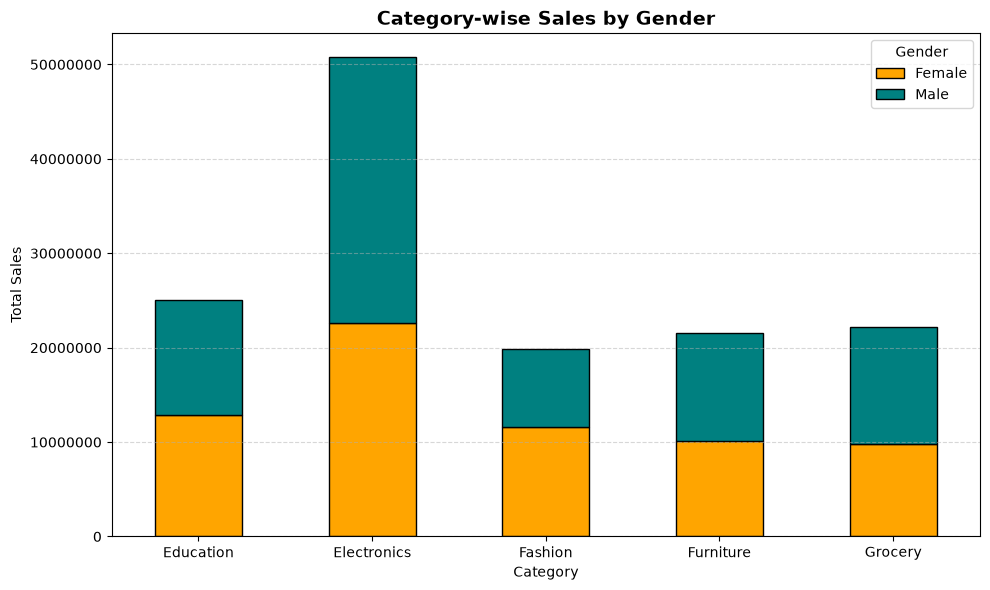

In [26]:

data = df.groupby(["Category", "Gender"])["Total_Sales"].sum().unstack()

ax = data.plot(kind="bar", stacked=True, figsize=(10, 6),
               color=["orange", "teal"], edgecolor="black")

plt.title("Category-wise Sales by Gender", fontsize=14, fontweight="bold")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.ticklabel_format(axis="y", style="plain")
plt.legend(title="Gender")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

